In [2]:
# Import Libraries

import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

In [10]:
url = "https://www.worldometers.info/world-population/population-by-country/"

headers = {
    'User-Agent': (
        'MyScraperBot/1.0 (https://example.com/contact; myemail@example.com)'
    )
}

response = requests.get(url, headers=headers, timeout=20)

print(response.status_code)

200


In [11]:
soup = BeautifulSoup(response.text, "html.parser")

print("Page title:")
print(soup.title.get_text(strip=True) if soup.title else "Title not found")

Page title:
Population by Country (2026) - Worldometer


In [12]:
print("First 10 headings:")

headings = soup.find_all(["h1", "h2", "h3"])

for heading in headings[:10]:
    print(heading.get_text(" ", strip=True))

First 10 headings:
Countries in the world by population (2026)


In [13]:
tables = pd.read_html(response.text)

print("Number of tables found:", len(tables))

Number of tables found: 1


/tmp/ipykernel_1978/4081976331.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


In [14]:
for i, table in enumerate(tables):
    print(f"\nTable {i + 1}")
    display(table.head())


Table 1


,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
0,1,India,1476625576,0.87%,12760051,497,2973190,"â440,456",1.93,29.2,37.6%,17.8%
1,2,China,1412914089,â0.22%,"â3,182,005",150,9388211,"â232,107",1.03,40.6,68.7%,17%
2,3,United States,349035494,0.51%,1759687,38,9147420,1177848,1.63,38.7,83.1%,4.2%
3,4,Indonesia,287886782,0.76%,2165546,159,1811570,"â39,472",2.08,30.7,60.3%,3.5%
4,5,Pakistan,259299791,1.6%,4080237,336,770880,"â1,144,738",3.44,20.8,34.7%,3.1%


In [15]:
# Here, we will select the first table as it contains useful information about exoplanets

In [16]:
df = tables[0].copy()
df.head()

,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
0,1,India,1476625576,0.87%,12760051,497,2973190,"â440,456",1.93,29.2,37.6%,17.8%
1,2,China,1412914089,â0.22%,"â3,182,005",150,9388211,"â232,107",1.03,40.6,68.7%,17%
2,3,United States,349035494,0.51%,1759687,38,9147420,1177848,1.63,38.7,83.1%,4.2%
3,4,Indonesia,287886782,0.76%,2165546,159,1811570,"â39,472",2.08,30.7,60.3%,3.5%
4,5,Pakistan,259299791,1.6%,4080237,336,770880,"â1,144,738",3.44,20.8,34.7%,3.1%


In [17]:
print("Dataset shape:", df.shape)

Dataset shape: (234, 12)


In [18]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['#', 'Country (or dependency)', 'Population 2026', 'Yearly Change', 'Net Change', 'Density (P/KmÂ²)', 'Land Area (KmÂ²)', 'Migrants (net)', 'Fert. Rate', 'Median Age', 'Urban Pop %', 'World Share']


In [19]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   #                        234 non-null    int64  
 1   Country (or dependency)  234 non-null    object 
 2   Population 2026          234 non-null    int64  
 3   Yearly Change            234 non-null    object 
 4   Net Change               234 non-null    object 
 5   Density (P/KmÂ²)         234 non-null    int64  
 6   Land Area (KmÂ²)         234 non-null    int64  
 7   Migrants (net)           234 non-null    object 
 8   Fert. Rate               234 non-null    float64
 9   Median Age               234 non-null    float64
 10  Urban Pop %              234 non-null    object 
 11  World Share              234 non-null    object 
dtypes: float64(2), int64(4), object(6)
memory usage: 22.1+ KB


In [20]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
#                          0
Country (or dependency)    0
Population 2026            0
Yearly Change              0
Net Change                 0
Density (P/KmÂ²)           0
Land Area (KmÂ²)           0
Migrants (net)             0
Fert. Rate                 0
Median Age                 0
Urban Pop %                0
World Share                0
dtype: int64


In [22]:
# Save the scraped dataset

df.to_csv("world_data.csv", index=False)

In [24]:
## Make a copy so the original scraped data stays unchanged
clean_df = df.copy()

# Columns that should contain numeric values
numeric_columns = [
    "Population 2026",
    "Yearly Change",
    "Net Change",
    "Density (P/KmÂ²)",
    "Land Area (KmÂ²)",
    "Migrants (net)",
    "Fert. Rate",
    "Median Age",
    "Urban Pop %",
    "World Share"
]

# Remove percentage signs, commas and citation markers,
# then convert the values to numbers
for column in numeric_columns:
    clean_df[column] = (
        clean_df[column]
        .astype(str)
        .str.replace(r"\[\d+\]", "", regex=True)
        .str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.strip()
    )

    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="coerce"
    )

print("Data cleaning completed!")
print(clean_df.info())
print(clean_df.head())

Data cleaning completed!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   #                        234 non-null    int64  
 1   Country (or dependency)  234 non-null    object 
 2   Population 2026          234 non-null    int64  
 3   Yearly Change            172 non-null    float64
 4   Net Change               172 non-null    float64
 5   Density (P/KmÂ²)         234 non-null    int64  
 6   Land Area (KmÂ²)         234 non-null    int64  
 7   Migrants (net)           100 non-null    float64
 8   Fert. Rate               234 non-null    float64
 9   Median Age               234 non-null    float64
 10  Urban Pop %              210 non-null    float64
 11  World Share              234 non-null    float64
dtypes: float64(7), int64(4), object(1)
memory usage: 22.1+ KB
None
   # Country (or dependency)  Population 2026 

In [25]:
print("Updated data types:")
print(clean_df[numeric_columns].dtypes)

Updated data types:
Population 2026       int64
Yearly Change       float64
Net Change          float64
Density (P/KmÂ²)      int64
Land Area (KmÂ²)      int64
Migrants (net)      float64
Fert. Rate          float64
Median Age          float64
Urban Pop %         float64
World Share         float64
dtype: object


In [26]:
clean_df.head()

,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
0,1,India,1476625576,0.87,12760051.0,497,2973190,NaN,1.93,29.2,37.6,17.8
1,2,China,1412914089,NaN,NaN,150,9388211,NaN,1.03,40.6,68.7,17.0
2,3,United States,349035494,0.51,1759687.0,38,9147420,1177848.0,1.63,38.7,83.1,4.2
3,4,Indonesia,287886782,0.76,2165546.0,159,1811570,NaN,2.08,30.7,60.3,3.5
4,5,Pakistan,259299791,1.60,4080237.0,336,770880,NaN,3.44,20.8,34.7,3.1


In [27]:
print("Missing values after numeric conversion:")
print(clean_df.isnull().sum())

Missing values after numeric conversion:
#                            0
Country (or dependency)      0
Population 2026              0
Yearly Change               62
Net Change                  62
Density (P/KmÂ²)             0
Land Area (KmÂ²)             0
Migrants (net)             134
Fert. Rate                   0
Median Age                   0
Urban Pop %                 24
World Share                  0
dtype: int64


In [28]:
# Create a list of numeric and text columns

numeric_columns = clean_df.select_dtypes(include="number").columns
text_columns = clean_df.select_dtypes(include="object").columns

# Fill missing numeric values with the median

for column in numeric_columns:
    clean_df[column] = clean_df[column].fillna(
        clean_df[column].median()
    )

# Fill missing text values with the mode

for column in text_columns:
    if clean_df[column].isnull().sum() > 0:
        clean_df[column] = clean_df[column].fillna(
            clean_df[column].mode()[0]
        )

print("Missing values remaining:")
print(clean_df.isnull().sum())

Missing values remaining:
#                          0
Country (or dependency)    0
Population 2026            0
Yearly Change              0
Net Change                 0
Density (P/KmÂ²)           0
Land Area (KmÂ²)           0
Migrants (net)             0
Fert. Rate                 0
Median Age                 0
Urban Pop %                0
World Share                0
dtype: int64


In [29]:
# Save the clean dataset that we are going to use

clean_df.to_csv("world_cleaned_data.csv", index=False)

In [30]:
# Select numerical columns for statistical analysis

numeric_df = clean_df.select_dtypes(include="number")

print("Numerical columns:")
print(numeric_df.columns.tolist())

print("\nNumber of numerical columns:", len(numeric_df.columns))

Numerical columns:
['#', 'Population 2026', 'Yearly Change', 'Net Change', 'Density (P/KmÂ²)', 'Land Area (KmÂ²)', 'Migrants (net)', 'Fert. Rate', 'Median Age', 'Urban Pop %', 'World Share']

Number of numerical columns: 11


In [31]:
print("Statistical summary:")
print(numeric_df.describe())

Statistical summary:
                #  Population 2026  Yearly Change    Net Change  \
count  234.000000     2.340000e+02     234.000000  2.340000e+02   
mean   117.500000     3.546514e+07       1.310385  3.450814e+05   
std     67.694165     1.394742e+08       0.764693  1.028640e+06   
min      1.000000     5.060000e+02       0.020000  1.000000e+00   
25%     59.250000     4.389268e+05       0.812500  2.281675e+04   
50%    117.500000     5.776466e+06       1.180000  8.406500e+04   
75%    175.750000     2.428835e+07       1.767500  2.238390e+05   
max    234.000000     1.476626e+09       3.370000  1.276005e+07   

       Density (P/KmÂ²)  Land Area (KmÂ²)  Migrants (net)  Fert. Rate  \
count        234.000000      2.340000e+02    2.340000e+02  234.000000   
mean         488.927350      5.559568e+05    2.480477e+04    2.282735   
std         2402.936254      1.691024e+06    9.083342e+04    1.103612   
min            0.000000      0.000000e+00    0.000000e+00    0.700000   
25%       

In [32]:
statistics = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Variance": numeric_df.var(),
    "Standard Deviation": numeric_df.std()
})

statistics

,Mean,Median,Mode,Variance,Standard Deviation
#,1.175000e+02,117.500,1.00,4.582500e+03,6.769417e+01
Population 2026,3.546514e+07,5776466.500,506.00,1.945304e+16,1.394742e+08
Yearly Change,1.310385e+00,1.180,1.18,5.847556e-01,7.646932e-01
Net Change,3.450814e+05,84065.000,84065.00,1.058100e+12,1.028640e+06
Density (P/KmÂ²),4.889274e+02,100.000,4.00,5.774103e+06,2.402936e+03
Land Area (KmÂ²),5.559568e+05,79720.000,460.00,2.859561e+12,1.691024e+06
Migrants (net),2.480477e+04,6621.000,6621.00,8.250710e+09,9.083342e+04
Fert. Rate,2.282735e+00,1.925,1.47,1.217959e+00,1.103612e+00
Median Age,3.221838e+01,33.350,39.10,9.815309e+01,9.907224e+00
Urban Pop %,6.126453e+01,62.400,62.40,4.551345e+02,2.133388e+01


In [33]:
Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1
print("Interquartile Range (IQR):")
print(IQR)

Interquartile Range (IQR):
#                   1.165000e+02
Population 2026     2.384943e+07
Yearly Change       9.550000e-01
Net Change          2.010222e+05
Density (P/KmÂ²)    2.210000e+02
Land Area (KmÂ²)    4.044300e+05
Migrants (net)      0.000000e+00
Fert. Rate          1.412500e+00
Median Age          1.715000e+01
Urban Pop %         3.350000e+01
World Share         2.896750e-01
dtype: float64


In [34]:
# Visualisation

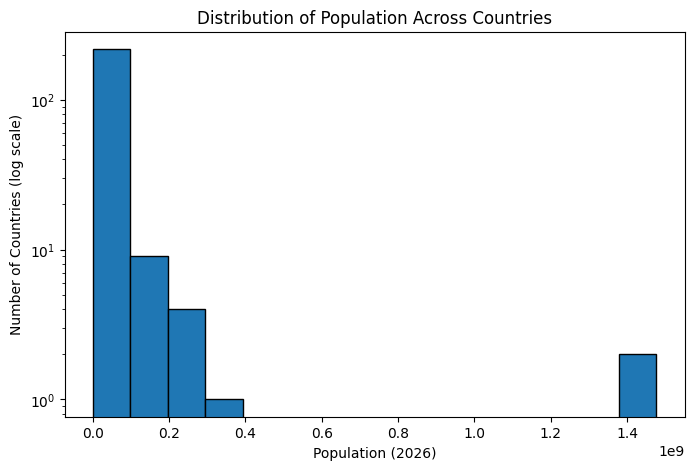

In [37]:
plt.figure(figsize=(8, 5))

plt.hist(
    clean_df["Population 2026"],
    bins=15,
    edgecolor="black",
    log=True
)

plt.title("Distribution of Population Across Countries")
plt.xlabel("Population (2026)")
plt.ylabel("Number of Countries (log scale)")

plt.show()

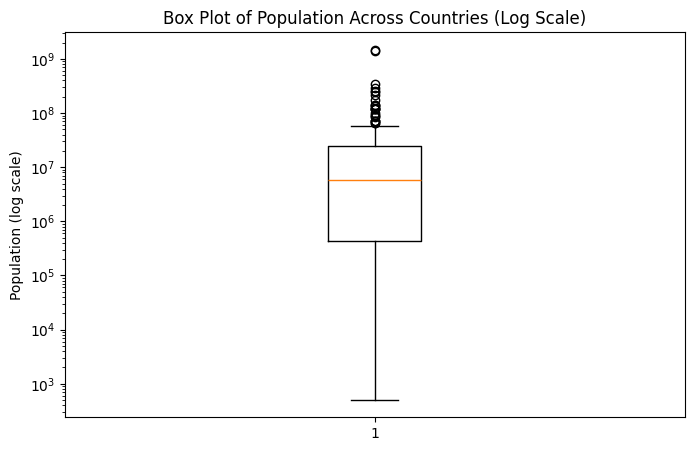

In [38]:
# Box plot

plt.figure(figsize=(8, 5))

plt.boxplot(clean_df["Population 2026"].dropna())

plt.yscale("log")
plt.title("Box Plot of Population Across Countries (Log Scale)")
plt.ylabel("Population (log scale)")

plt.show()

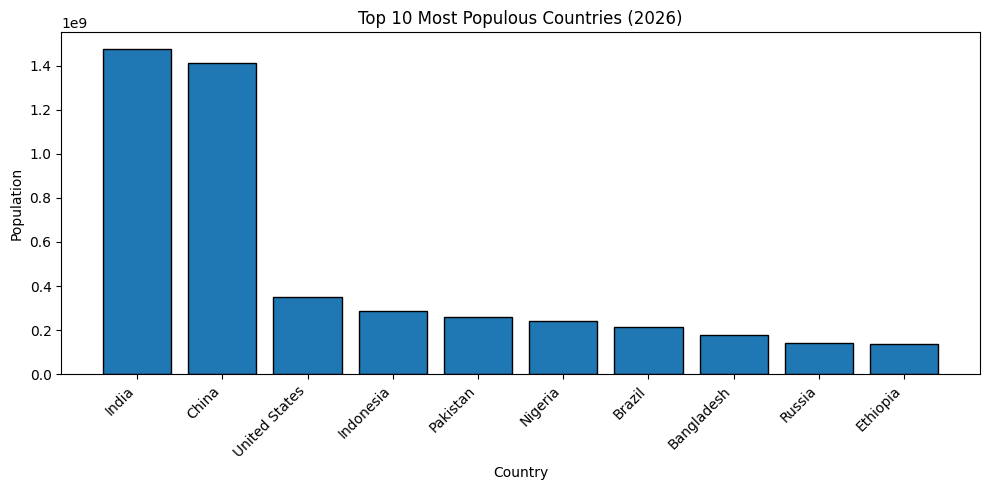

In [39]:
# Bar chart

# Get the 10 most populous countries
country_counts = (
    clean_df.nlargest(10, "Population 2026")
    .set_index("Country (or dependency)")["Population 2026"]
)

plt.figure(figsize=(10, 5))

plt.bar(
    country_counts.index,
    country_counts.values,
    edgecolor="black"
)

plt.title("Top 10 Most Populous Countries (2026)")
plt.xlabel("Country")
plt.ylabel("Population")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

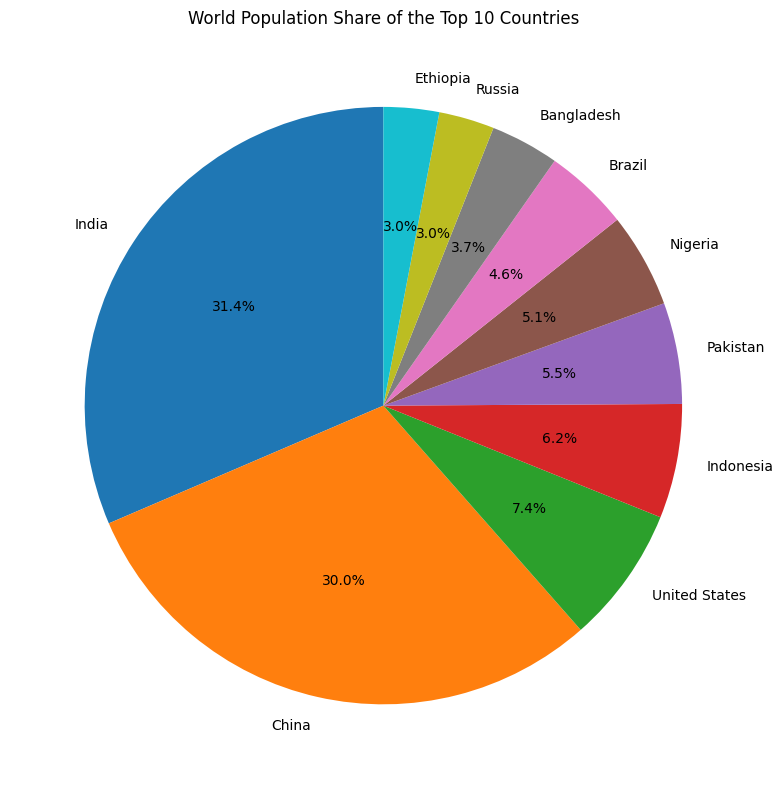

In [40]:
# Pie Chart

# Get the 10 countries with the largest world population shares
share_counts = (
    clean_df.nlargest(10, "Population 2026")
    .set_index("Country (or dependency)")["World Share"]
)

plt.figure(figsize=(8, 8))

plt.pie(
    share_counts,
    labels=share_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("World Population Share of the Top 10 Countries")
plt.tight_layout()
plt.show()

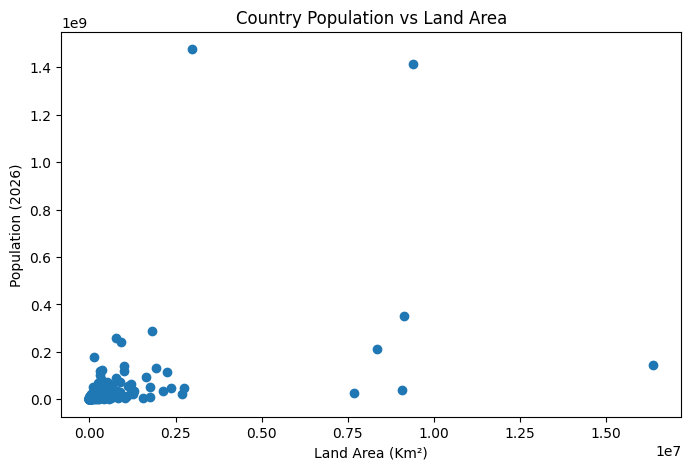

In [41]:
# Scatter Plot

plt.figure(figsize=(8, 5))

plt.scatter(
    clean_df["Land Area (KmÂ²)"],
    clean_df["Population 2026"]
)

plt.title("Country Population vs Land Area")
plt.xlabel("Land Area (Km²)")
plt.ylabel("Population (2026)")

plt.show()

In [42]:
# Probability Distribution and Sampling

In [43]:
# Simple Random Sampling

sample1 = clean_df.sample(n=20, random_state=1)
sample1

,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
199,200,Isle of Man,84055,1.18,84065.0,147,570,158.0,1.53,46.3,57.3,0.001000
69,70,Romania,18800605,1.18,84065.0,82,230170,6621.0,1.71,43.5,55.5,0.230000
233,234,Holy See,506,1.00,5.0,1265,0,13.0,1.00,56.2,62.4,0.000006
39,40,Ukraine,39535849,1.43,555473.0,68,579320,6621.0,1.00,41.8,75.5,0.480000
138,139,Moldova,2961253,1.18,84065.0,90,32850,6621.0,1.72,39.1,58.5,0.040000
174,175,Brunei,469775,0.74,3445.0,89,5270,8.0,1.70,33.2,80.6,0.005700
90,91,Sweden,10701047,0.42,44414.0,26,410340,42755.0,1.45,40.4,87.7,0.130000
67,68,Senegal,19366548,2.30,434582.0,101,192530,6621.0,3.66,19.8,53.0,0.230000
119,120,Oman,5671458,3.22,176767.0,18,309500,79740.0,2.44,29.8,89.6,0.070000
73,74,Zimbabwe,17273580,1.90,322785.0,45,386850,6621.0,3.57,18.3,38.2,0.210000


In [44]:
# Random Sampling With Replacement

sample2 = clean_df.sample(n=20, replace=True, random_state=1)
sample2

,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
37,38,Canada,40467728,0.85,341005.0,4,9093510,291403.0,1.33,40.8,80.2,0.49000
140,141,Gambia,2884079,2.20,61986.0,285,10120,6621.0,3.70,18.8,62.2,0.03000
72,73,Cambodia,18051219,1.14,203237.0,102,176520,6621.0,2.49,26.4,26.9,0.22000
137,138,Bosnia and Herzegovina,3114242,1.18,84065.0,61,51000,6621.0,1.50,46.1,57.1,0.04000
203,204,Dominica,65511,1.18,84065.0,87,750,6621.0,1.46,36.6,85.6,0.00079
133,134,Uruguay,3382537,1.18,84065.0,19,175020,6621.0,1.38,36.7,62.4,0.04000
79,80,South Sudan,12436037,2.03,247249.0,20,610952,7974.0,3.63,19.0,28.3,0.15000
192,193,Seychelles,134959,1.64,2180.0,293,460,1367.0,2.06,34.6,43.4,0.00160
144,145,Gabon,2647399,2.09,54269.0,10,257670,1152.0,3.49,21.6,83.8,0.03000
129,130,Croatia,3822345,1.18,84065.0,68,55960,6621.0,1.47,45.5,62.2,0.05000


In [45]:
# Random Sampling Without Replacement

sample3 = clean_df.sample(n=20, replace=False, random_state=1)
sample3

,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
199,200,Isle of Man,84055,1.18,84065.0,147,570,158.0,1.53,46.3,57.3,0.001000
69,70,Romania,18800605,1.18,84065.0,82,230170,6621.0,1.71,43.5,55.5,0.230000
233,234,Holy See,506,1.00,5.0,1265,0,13.0,1.00,56.2,62.4,0.000006
39,40,Ukraine,39535849,1.43,555473.0,68,579320,6621.0,1.00,41.8,75.5,0.480000
138,139,Moldova,2961253,1.18,84065.0,90,32850,6621.0,1.72,39.1,58.5,0.040000
174,175,Brunei,469775,0.74,3445.0,89,5270,8.0,1.70,33.2,80.6,0.005700
90,91,Sweden,10701047,0.42,44414.0,26,410340,42755.0,1.45,40.4,87.7,0.130000
67,68,Senegal,19366548,2.30,434582.0,101,192530,6621.0,3.66,19.8,53.0,0.230000
119,120,Oman,5671458,3.22,176767.0,18,309500,79740.0,2.44,29.8,89.6,0.070000
73,74,Zimbabwe,17273580,1.90,322785.0,45,386850,6621.0,3.57,18.3,38.2,0.210000


In [46]:
# Fraction Sampling

sample4 = clean_df.sample(frac=0.20, random_state=1)
sample4

,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
199,200,Isle of Man,84055,1.18,84065.0,147,570,158.0,1.53,46.3,57.3,0.001000
69,70,Romania,18800605,1.18,84065.0,82,230170,6621.0,1.71,43.5,55.5,0.230000
233,234,Holy See,506,1.00,5.0,1265,0,13.0,1.00,56.2,62.4,0.000006
39,40,Ukraine,39535849,1.43,555473.0,68,579320,6621.0,1.00,41.8,75.5,0.480000
138,139,Moldova,2961253,1.18,84065.0,90,32850,6621.0,1.72,39.1,58.5,0.040000
174,175,Brunei,469775,0.74,3445.0,89,5270,8.0,1.70,33.2,80.6,0.005700
90,91,Sweden,10701047,0.42,44414.0,26,410340,42755.0,1.45,40.4,87.7,0.130000
67,68,Senegal,19366548,2.30,434582.0,101,192530,6621.0,3.66,19.8,53.0,0.230000
119,120,Oman,5671458,3.22,176767.0,18,309500,79740.0,2.44,29.8,89.6,0.070000
73,74,Zimbabwe,17273580,1.90,322785.0,45,386850,6621.0,3.57,18.3,38.2,0.210000


In [47]:
print("Sample size:", len(sample4))

Sample size: 47


In [48]:
# Systematic Random Sampling

k = 5

systematic_sample = clean_df.iloc[::k]
systematic_sample

,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
0,1,India,1476625576,0.87,12760051.0,497,2973190,6621.0,1.93,29.2,37.6,17.800000
5,6,Nigeria,242431832,2.06,4904050.0,266,910770,6621.0,4.21,18.3,55.8,2.900000
10,11,Mexico,132997658,0.80,1050758.0,68,1943950,6621.0,1.85,30.0,88.3,1.600000
15,16,Vietnam,102177431,0.57,578904.0,330,310070,6621.0,1.86,33.9,42.2,1.200000
20,21,Thailand,71559614,1.18,84065.0,140,510890,29200.0,1.19,41.0,54.3,0.860000
25,26,Kenya,58636412,1.92,1103919.0,103,569140,6621.0,3.07,20.3,32.6,0.710000
30,31,South Korea,51600388,1.18,84065.0,531,97230,62644.0,0.76,46.2,82.8,0.620000
35,36,Afghanistan,45047069,2.74,1202958.0,69,652860,6621.0,4.56,17.4,26.9,0.540000
40,41,Morocco,38762441,0.86,331671.0,87,446300,6621.0,2.16,30.1,67.9,0.470000
45,46,Ghana,35697557,1.81,633285.0,157,227540,6621.0,3.26,21.6,59.2,0.430000


In [49]:
print("Sample size:", len(systematic_sample))

Sample size: 47


In [51]:
# Stratified Sampling

# Take a 20% random sample of countries
sample5 = clean_df.sample(frac=0.20, random_state=1)

sample5

,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share
199,200,Isle of Man,84055,1.18,84065.0,147,570,158.0,1.53,46.3,57.3,0.001000
69,70,Romania,18800605,1.18,84065.0,82,230170,6621.0,1.71,43.5,55.5,0.230000
233,234,Holy See,506,1.00,5.0,1265,0,13.0,1.00,56.2,62.4,0.000006
39,40,Ukraine,39535849,1.43,555473.0,68,579320,6621.0,1.00,41.8,75.5,0.480000
138,139,Moldova,2961253,1.18,84065.0,90,32850,6621.0,1.72,39.1,58.5,0.040000
174,175,Brunei,469775,0.74,3445.0,89,5270,8.0,1.70,33.2,80.6,0.005700
90,91,Sweden,10701047,0.42,44414.0,26,410340,42755.0,1.45,40.4,87.7,0.130000
67,68,Senegal,19366548,2.30,434582.0,101,192530,6621.0,3.66,19.8,53.0,0.230000
119,120,Oman,5671458,3.22,176767.0,18,309500,79740.0,2.44,29.8,89.6,0.070000
73,74,Zimbabwe,17273580,1.90,322785.0,45,386850,6621.0,3.57,18.3,38.2,0.210000


In [52]:
print("Sample size:", len(sample5))

Sample size: 47


In [53]:
# Cluster Sampling

# Divide countries into population groups
clean_df["Population Group"] = pd.cut(
    clean_df["Population 2026"],
    bins=[0, 1_000_000, 10_000_000, 100_000_000, float("inf")],
    labels=["Under 1M", "1M–10M", "10M–100M", "Over 100M"]
)

# Randomly select two population groups
clusters = np.random.choice(
    clean_df["Population Group"].dropna().unique(),
    size=2,
    replace=False
)

# Select countries belonging to those groups
cluster_sample = clean_df[
    clean_df["Population Group"].isin(clusters)
]

print("Selected population groups:", clusters)
print("Number of countries selected:", len(cluster_sample))

cluster_sample.head()

Selected population groups: ['Over 100M' '1M–10M']
Number of countries selected: 82


,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share,Population Group
0,1,India,1476625576,0.87,12760051.0,497,2973190,6621.0,1.93,29.2,37.6,17.8,Over 100M
1,2,China,1412914089,1.18,84065.0,150,9388211,6621.0,1.03,40.6,68.7,17.0,Over 100M
2,3,United States,349035494,0.51,1759687.0,38,9147420,1177848.0,1.63,38.7,83.1,4.2,Over 100M
3,4,Indonesia,287886782,0.76,2165546.0,159,1811570,6621.0,2.08,30.7,60.3,3.5,Over 100M
4,5,Pakistan,259299791,1.60,4080237.0,336,770880,6621.0,3.44,20.8,34.7,3.1,Over 100M


In [54]:
cluster_sample

,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share,Population Group
0,1,India,1476625576,0.87,12760051.0,497,2973190,6621.0,1.93,29.2,37.6,17.80,Over 100M
1,2,China,1412914089,1.18,84065.0,150,9388211,6621.0,1.03,40.6,68.7,17.00,Over 100M
2,3,United States,349035494,0.51,1759687.0,38,9147420,1177848.0,1.63,38.7,83.1,4.20,Over 100M
3,4,Indonesia,287886782,0.76,2165546.0,159,1811570,6621.0,2.08,30.7,60.3,3.50,Over 100M
4,5,Pakistan,259299791,1.60,4080237.0,336,770880,6621.0,3.44,20.8,34.7,3.10,Over 100M
...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,156,Cyprus,1382334,0.84,11580.0,150,9240,7210.0,1.37,39.1,61.1,0.02,1M–10M
156,157,Estonia,1331062,1.18,84065.0,31,42390,6621.0,1.38,43.2,67.5,0.02,1M–10M
157,158,Eswatini,1269859,1.09,13685.0,74,17200,6621.0,2.64,22.7,31.7,0.02,1M–10M
158,159,Mauritius,1265059,1.18,84065.0,623,2030,6621.0,1.21,38.3,41.8,0.02,1M–10M


In [55]:
# Population Mean

population_mean = clean_df["Population 2026"].mean()

print("Population Mean:", population_mean)

Population Mean: 35465139.68376068


In [56]:
# Select 10 random exoplanets

random_sample = clean_df.sample(n=10, random_state=42)

print("Random Sample of 10 countries:")
random_sample

Random Sample of 10 countries:


,#,Country (or dependency),Population 2026,Yearly Change,Net Change,Density (P/KmÂ²),Land Area (KmÂ²),Migrants (net),Fert. Rate,Median Age,Urban Pop %,World Share,Population Group
69,70,Romania,18800605,1.18,84065.0,82,230170,6621.0,1.71,43.5,55.5,0.23000,10M–100M
206,207,Greenland,55629,1.18,84065.0,0,410450,6621.0,1.90,35.5,91.2,0.00067,Under 1M
180,181,Vanuatu,342564,2.21,7395.0,28,12190,6621.0,3.50,20.3,25.5,0.00410,Under 1M
9,10,Ethiopia,138902185,2.53,3430134.0,139,1000000,27298.0,3.72,19.3,22.9,1.70000,Over 100M
127,128,Kuwait,5102773,1.53,76695.0,286,17820,30696.0,1.49,34.8,91.3,0.06000,1M–10M
109,110,Bulgaria,6667659,1.18,84065.0,61,108560,6621.0,1.74,45.0,77.4,0.08000,1M–10M
196,197,Tonga,103291,1.18,84065.0,143,720,6621.0,3.04,21.0,26.4,0.00120,Under 1M
93,94,Portugal,10395362,1.18,84065.0,113,91590,16968.0,1.52,47.2,66.9,0.13000,10M–100M
213,214,Liechtenstein,40368,0.60,240.0,252,160,193.0,1.54,44.7,14.8,0.00049,Under 1M
15,16,Vietnam,102177431,0.57,578904.0,330,310070,6621.0,1.86,33.9,42.2,1.20000,Over 100M


In [57]:

# Sample Mean

sample_mean = random_sample["Population 2026"].mean()

print("Sample Mean:", sample_mean)

Sample Mean: 28258786.7


In [58]:

# Comparison between population and sample

comparison = pd.DataFrame({
    "Statistics": ["Size", "Mean", "Median", "Standard Deviation"],

    "Population": [
        len(clean_df),
        clean_df["Population 2026"].mean(),
        clean_df["Population 2026"].median(),
        clean_df["Population 2026"].std()
    ],

    "Random Sample": [
        len(random_sample),
        random_sample["Population 2026"].mean(),
        random_sample["Population 2026"].median(),
        random_sample["Population 2026"].std()
    ]
})

comparison

,Statistics,Population,Random Sample
0,Size,2.340000e+02,1.000000e+01
1,Mean,3.546514e+07,2.825879e+07
2,Median,5.776466e+06,5.885216e+06
3,Standard Deviation,1.394742e+08,4.975564e+07


In [59]:
# Percentage Error

error = abs(
    (sample_mean - population_mean) / population_mean
) * 100

print("Percentage Error in Mean:", error, "%")

Percentage Error in Mean: 20.31953926593566 %


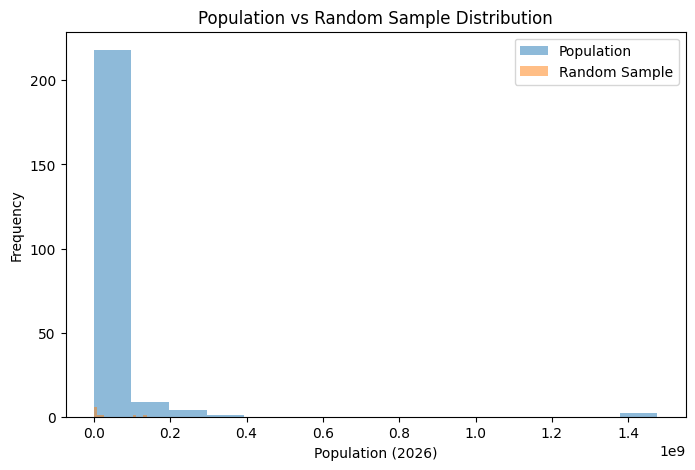

In [60]:
# Compare the distributions

plt.figure(figsize=(8, 5))

plt.hist(
    clean_df["Population 2026"].dropna(),
    bins=15,
    alpha=0.5,
    label="Population"
)

plt.hist(
    random_sample["Population 2026"].dropna(),
    bins=15,
    alpha=0.5,
    label="Random Sample"
)

plt.xlabel("Population (2026)")
plt.ylabel("Frequency")
plt.title("Population vs Random Sample Distribution")
plt.legend()

plt.show()

In [61]:
# Repeated Sampling

population_data = clean_df["Population 2026"].dropna()

means = []

for i in range(100):
    sample = population_data.sample(n=30, replace=True, random_state=i)
    means.append(sample.mean())

print("Number of sample means:", len(means))
print("Average of sample means:", np.mean(means))

Number of sample means: 100
Average of sample means: 34846462.42733333


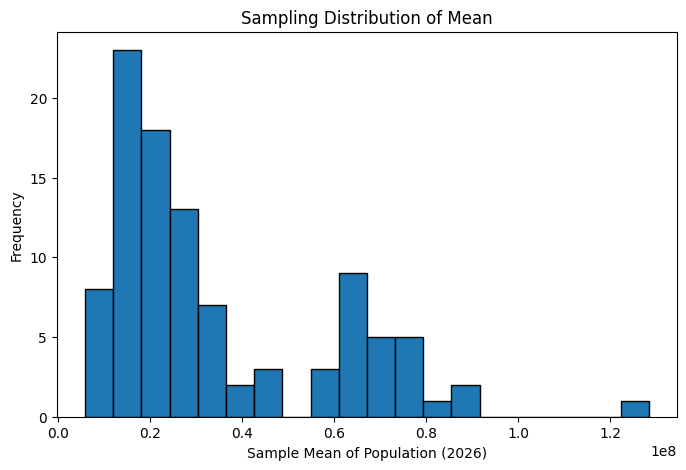

In [62]:
# Plot Sampling Distribution

plt.figure(figsize=(8, 5))

plt.hist(means, bins=20, edgecolor="black")

plt.title("Sampling Distribution of Mean")
plt.xlabel("Sample Mean of Population (2026)")
plt.ylabel("Frequency")

plt.show()

[5.53055835e+08 1.40384909e+09 1.08088111e+09 8.83994632e+08
 2.30381542e+08 2.30345926e+08 8.57682239e+07 1.27901792e+09
 8.87622002e+08 1.04555823e+09 3.03960863e+07 1.43219371e+09
 1.22920618e+09 3.13545760e+08 2.68487811e+08 2.70820203e+08
 4.49252229e+08 7.74869009e+08 6.37821349e+08 4.30036756e+08
 9.03477829e+08 2.05980638e+08 4.31388618e+08 5.40979588e+08
 6.73444878e+08 1.15941101e+09 2.94843819e+08 7.59331970e+08
 8.74774710e+08 6.85903499e+07 8.97116465e+08 2.51800702e+08
 9.60573190e+07 1.40114868e+09 1.42587697e+09 1.19370030e+09
 4.49800834e+08 1.44225598e+08 1.01035615e+09 6.49940713e+08
 1.80205223e+08 7.31191146e+08 5.07794584e+07 1.34272581e+09
 3.82121514e+08 9.78297521e+08 4.60280896e+08 7.67945984e+08
 8.07286611e+08 2.72961229e+08 1.43171347e+09 1.14458107e+09
 1.38728820e+09 1.32132500e+09 8.82874604e+08 1.36126311e+09
 1.30670753e+08 2.89393714e+08 6.67842547e+07 4.80391428e+08
 5.73931136e+08 4.00681289e+08 1.22373509e+09 5.26791412e+08
 4.14835446e+08 8.013591

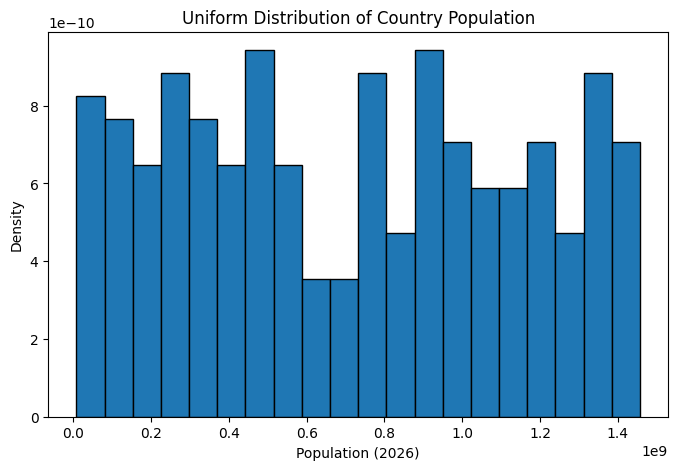

In [63]:
# Uniform Distribution for Host Star Temperatures

from scipy.stats import uniform

data = clean_df["Population 2026"].dropna()

loc = data.min()
scale = data.max() - data.min()

uniform_data = uniform.rvs(
    loc=loc,
    scale=scale,
    size=len(data),
    random_state=42
)

print(uniform_data)

print("Mean:", np.mean(uniform_data))
print("\nVariance:", np.var(uniform_data))

plt.figure(figsize=(8, 5))

plt.hist(
    uniform_data,
    bins=20,
    density=True,
    edgecolor="black"
)

plt.title("Uniform Distribution of Country Population")
plt.xlabel("Population (2026)")
plt.ylabel("Density")

plt.show()

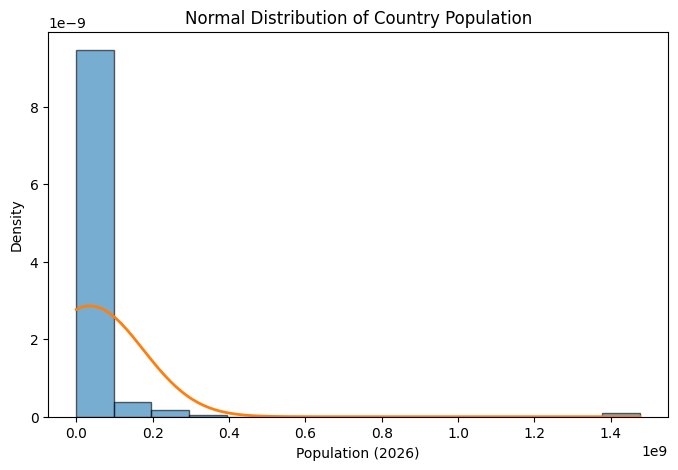

Mean: 35465139.68376068
Standard Deviation: 139474153.48610345


In [64]:
# Normal Distribution for Population

from scipy.stats import norm

population_data = clean_df["Population 2026"].dropna()

mean = population_data.mean()
std = population_data.std()

plt.figure(figsize=(8, 5))

plt.hist(
    population_data,
    bins=15,
    density=True,
    alpha=0.6,
    edgecolor="black"
)

x = np.linspace(population_data.min(), population_data.max(), 200)
y = norm.pdf(x, mean, std)

plt.plot(x, y, linewidth=2)

plt.title("Normal Distribution of Country Population")
plt.xlabel("Population (2026)")
plt.ylabel("Density")

plt.show()

print("Mean:", mean)
print("Standard Deviation:", std)

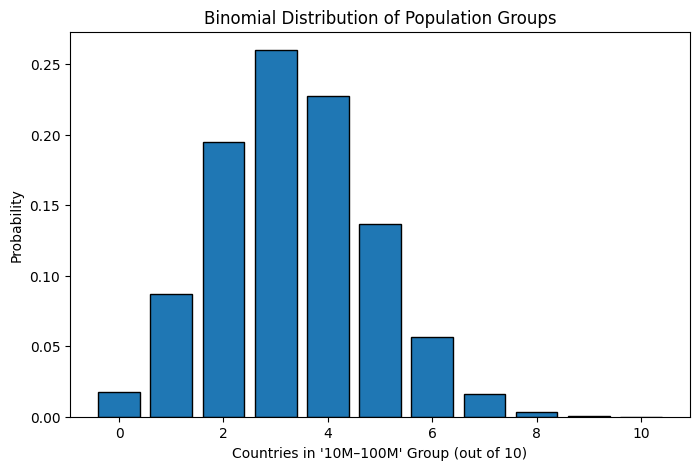

Most common population group: 10M–100M
Estimated probability: 0.3333333333333333


In [65]:
# Binomial Distribution for Discovery Method

from scipy.stats import binom

# Categorize countries by population
population_groups = pd.cut(
    clean_df["Population 2026"],
    bins=[0, 1_000_000, 10_000_000, 100_000_000, float("inf")],
    labels=["Under 1M", "1M–10M", "10M–100M", "Over 100M"]
)

group_counts = population_groups.value_counts()

most_common_group = group_counts.idxmax()
p = group_counts.max() / population_groups.notna().sum()

n = 10
x = np.arange(0, n + 1)
probabilities = binom.pmf(x, n, p)

plt.figure(figsize=(8, 5))

plt.bar(x, probabilities, edgecolor="black")

plt.title("Binomial Distribution of Population Groups")
plt.xlabel(f"Countries in '{most_common_group}' Group (out of 10)")
plt.ylabel("Probability")

plt.show()

print("Most common population group:", most_common_group)
print("Estimated probability:", p)

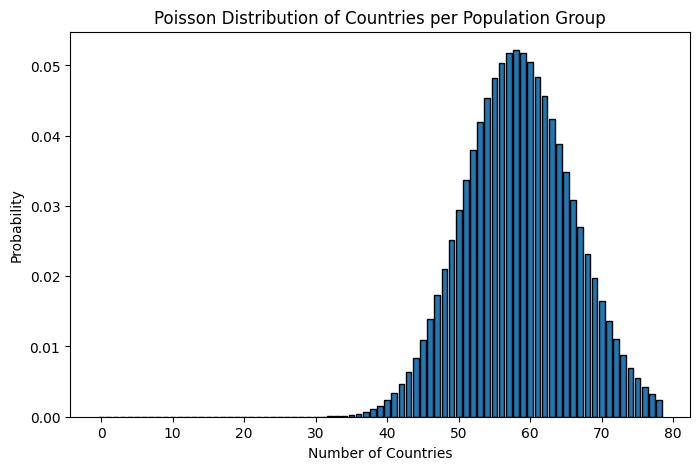

Estimated lambda: 58.5


In [66]:
# Poisson Distribution for Countries per Population Group

from scipy.stats import poisson

population_groups = pd.cut(
    clean_df["Population 2026"],
    bins=[0, 1_000_000, 10_000_000, 100_000_000, float("inf")],
    labels=["Under 1M", "1M–10M", "10M–100M", "Over 100M"]
)

group_counts = population_groups.value_counts()

lam = group_counts.mean()

x = np.arange(0, int(group_counts.max()) + 1)
probabilities = poisson.pmf(x, lam)

plt.figure(figsize=(8, 5))

plt.bar(x, probabilities, edgecolor="black")

plt.title("Poisson Distribution of Countries per Population Group")
plt.xlabel("Number of Countries")
plt.ylabel("Probability")

plt.show()

print("Estimated lambda:", lam)

In [67]:
# Central Limit Theorem

In [68]:
# Select population data

population_data = clean_df["Population 2026"].dropna()

# Calculate statistics

population_mean = population_data.mean()
population_std = population_data.std()

print("Total Countries:", len(population_data))
print("Population Mean:", population_mean)
print("Population Standard Deviation:", population_std)

Total Countries: 234
Population Mean: 35465139.68376068
Population Standard Deviation: 139474153.48610345


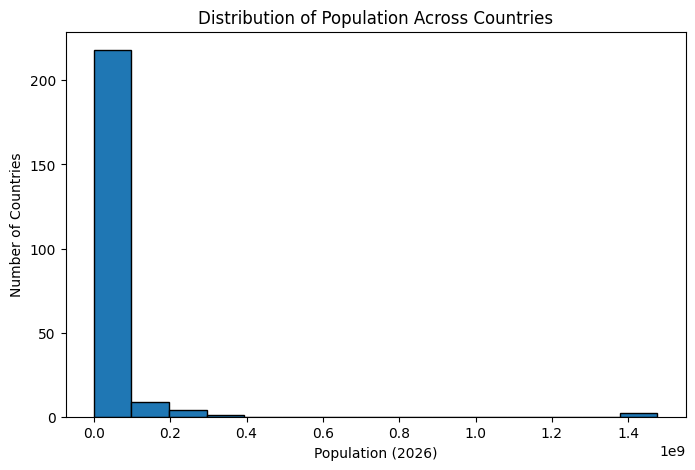

In [69]:
# Plot population distribution

plt.figure(figsize=(8, 5))

plt.hist(population_data, bins=15, edgecolor="black")

plt.title("Distribution of Population Across Countries")
plt.xlabel("Population (2026)")
plt.ylabel("Number of Countries")

plt.show()

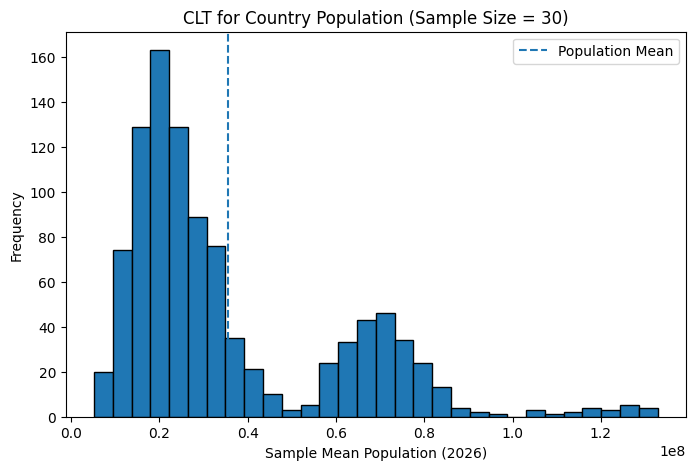

Sample Size: 30
Mean of Sample Means: 35982095.67823333
Standard Deviation of Sample Means: 24900038.100780033


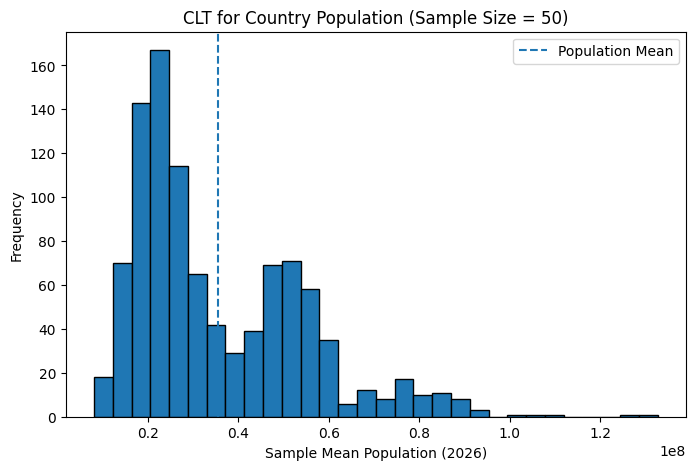

Sample Size: 50
Mean of Sample Means: 35679868.10744
Standard Deviation of Sample Means: 19176714.691381


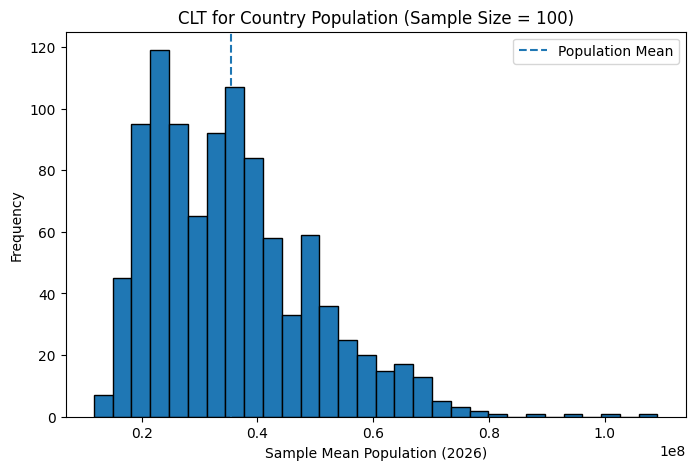

Sample Size: 100
Mean of Sample Means: 35526562.795940004
Standard Deviation of Sample Means: 13969039.33489897


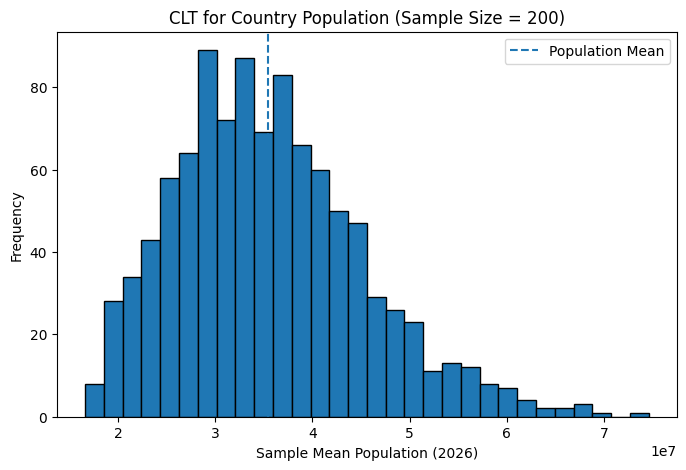

Sample Size: 200
Mean of Sample Means: 35526489.291205004
Standard Deviation of Sample Means: 9732763.573733794


In [70]:
# Central Limit Theorem for Country Population

sample_sizes = [30, 50, 100, 200]
number_of_samples = 1000

for n in sample_sizes:
    sample_means = []

    for i in range(number_of_samples):
        sample = population_data.sample(
            n=n,
            replace=True,
            random_state=i
        )
        sample_means.append(sample.mean())

    plt.figure(figsize=(8, 5))

    plt.hist(sample_means, bins=30, edgecolor="black")

    plt.axvline(
        population_mean,
        linestyle="--",
        label="Population Mean"
    )

    plt.title(
        "CLT for Country Population (Sample Size = " + str(n) + ")"
    )
    plt.xlabel("Sample Mean Population (2026)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

    print("Sample Size:", n)
    print("Mean of Sample Means:", np.mean(sample_means))
    print(
        "Standard Deviation of Sample Means:",
        np.std(sample_means)
    )

In [71]:
# Estimate Population Mean

estimated_mean = np.mean(sample_means)

print("Actual Dataset Mean:", population_mean)
print("Estimated Population Mean:", estimated_mean)

print(
    "Absolute Error:",
    abs(population_mean - estimated_mean)
)

Actual Dataset Mean: 35465139.68376068
Estimated Population Mean: 35526489.291205004
Absolute Error: 61349.6074443236


In [72]:
standard_error = population_std / np.sqrt(n)

print("Sample Size:", n)
print("Mean of Sample Means:", np.mean(sample_means))
print("Standard Error:", standard_error)
print("Standard Deviation of Sample Means:", np.std(sample_means))

Sample Size: 200
Mean of Sample Means: 35526489.291205004
Standard Error: 9862311.97302771
Standard Deviation of Sample Means: 9732763.573733794


In [73]:
# Hypothesis Testing

In [74]:
# Select country population data
data = clean_df["Population 2026"].dropna()

# Calculate basic statistics
n = len(data)

sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)

print("Sample Size:", n)
print("Sample Mean Population:", sample_mean)
print("Sample Standard Deviation:", sample_std)

Sample Size: 234
Sample Mean Population: 35465139.68376068
Sample Standard Deviation: 139474153.48610345


In [75]:
# Use t distribution

confidence = 0.95

standard_error = sample_std / np.sqrt(n)

In [76]:
# Calculate t critical value

t_critical = stats.t.ppf(
    (1 + confidence) / 2,
    df = n - 1
)

In [77]:
# Margin of error

margin_error = t_critical * standard_error

In [78]:
# Confidence interval

lower = sample_mean - margin_error
upper = sample_mean + margin_error

print("95% Confidence Interval:")

print("Lower Limit:", round(lower,2))
print("Upper Limit:", round(upper,2))

95% Confidence Interval:
Lower Limit: 17501448.06
Upper Limit: 53428831.3


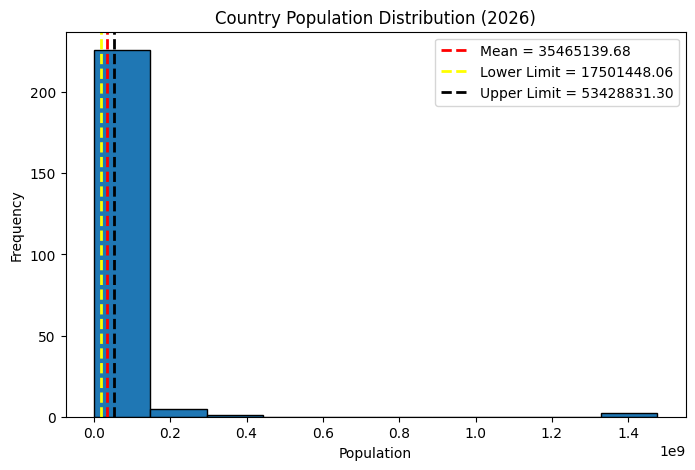

In [79]:
# Graph for country population distribution

plt.figure(figsize=(8, 5))

plt.hist(data, bins=10, edgecolor="black")

plt.axvline(
    sample_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {sample_mean:.2f}"
)

plt.axvline(
    lower,
    color="yellow",
    linestyle="--",
    linewidth=2,
    label=f"Lower Limit = {lower:.2f}"
)

plt.axvline(
    upper,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Upper Limit = {upper:.2f}"
)

plt.title("Country Population Distribution (2026)")
plt.xlabel("Population")
plt.ylabel("Frequency")
plt.legend()

plt.show()

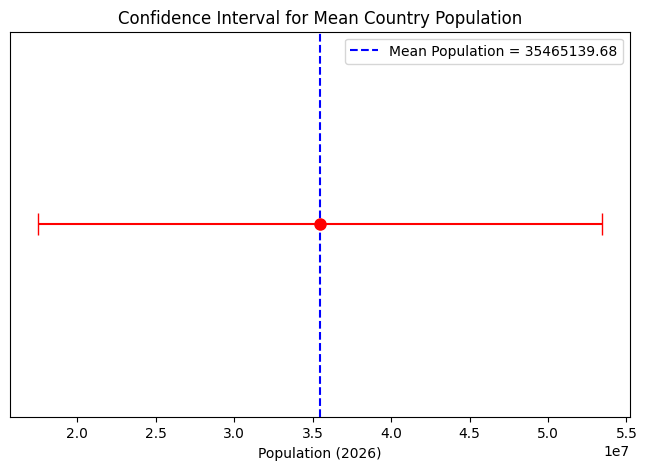

In [80]:
# Confidence interval graph for country population

plt.figure(figsize=(8, 5))

plt.errorbar(
    sample_mean,
    1,
    xerr=margin_error,
    fmt="o",
    color="red",
    capsize=8,
    markersize=8
)

plt.axvline(
    sample_mean,
    color="blue",
    linestyle="--",
    label=f"Mean Population = {sample_mean:.2f}"
)

plt.title("Confidence Interval for Mean Country Population")
plt.xlabel("Population (2026)")
plt.yticks([])
plt.legend()

plt.show()

In [81]:
# One Sample t - test

In [82]:
# Hypothesized population mean

mu = 5000

# Perform one-sample t-test

t_statistic, p_value = stats.ttest_1samp(data, popmean=mu)

# Display results

print("One-Sample t-test:")
print("T-statistic:", t_statistic)
print("P-value:", p_value)

One-Sample t-test:
T-statistic: 3.8891494879064474
P-value: 0.00013126372582438565


In [90]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("The mean country population is significantly different from 10,000,000.")

else:
    print("Fail to reject the null hypothesis")
    print("There is insufficient evidence that the mean country population differs from 10,000,000.")

Reject the null hypothesis
The mean country population is significantly different from 10,000,000.


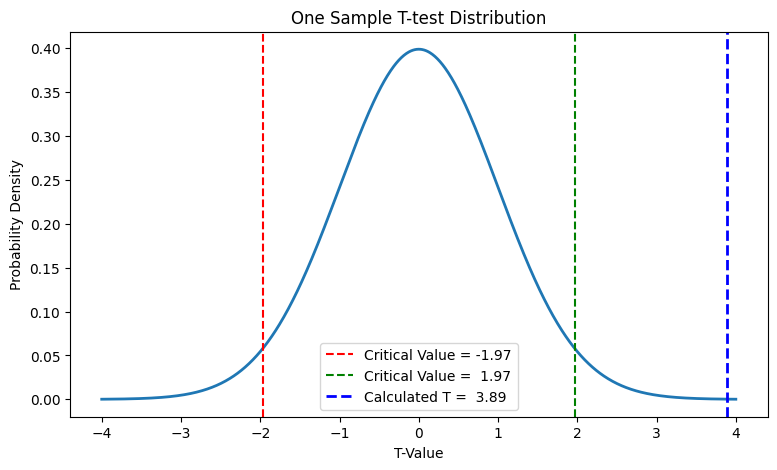

In [84]:
x_t = np.linspace(-4, 4, 1000)

y_t = stats.t.pdf(
    x_t,
    df = n - 1
)

plt.figure(figsize = (9,5))

plt.plot(
    x_t,
    y_t,
    linewidth = 2
)

# Critical values for alpha = 0.05

t_critical_test = stats.t.ppf(
    1 - alpha / 2,
    df = n - 1
)

plt.axvline(
    -t_critical_test,
    color = "red",
    linestyle = "--",
    label = f"Critical Value = {-t_critical_test : .2f}"
)

plt.axvline(
    t_critical_test,
    color = "green",
    linestyle = "--",
    label = f"Critical Value = {t_critical_test : .2f}"
)

plt.axvline(
    t_statistic,
    color = "blue",
    linestyle = "--",
    linewidth = 2,
    label = f"Calculated T = {t_statistic : .2f}"
)

plt.xlabel("T-Value")
plt.ylabel("Probability Density")
plt.title("One Sample T-test Distribution")
plt.legend()

plt.show()

In [85]:
# One Sample Z test

In [86]:
# Set hypothesized mean and estimated population standard deviation

mu = 10_000_000
population_std = clean_df["Population 2026"].std()

In [87]:
# Calculate Z statistic

z_score = ((sample_mean - mu) / (population_std / np.sqrt(n)))

# Calculate two tailed p value

p_value = 2 * (1 - stats.norm.cdf(np.abs(z_score)))

print("One Sample Z-test\n")
print("Z-score:", round(z_score, 4))
print("P-value:", round(p_value, 4))

One Sample Z-test

Z-score: 2.7929
P-value: 0.0052


In [89]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("The mean country population is significantly different from 10,000,000.")

else:
    print("Fail to reject the null hypothesis")
    print("There is insufficient evidence that the mean country population differs from 10,000,000.")

Reject the null hypothesis
The mean country population is significantly different from 10,000,000.


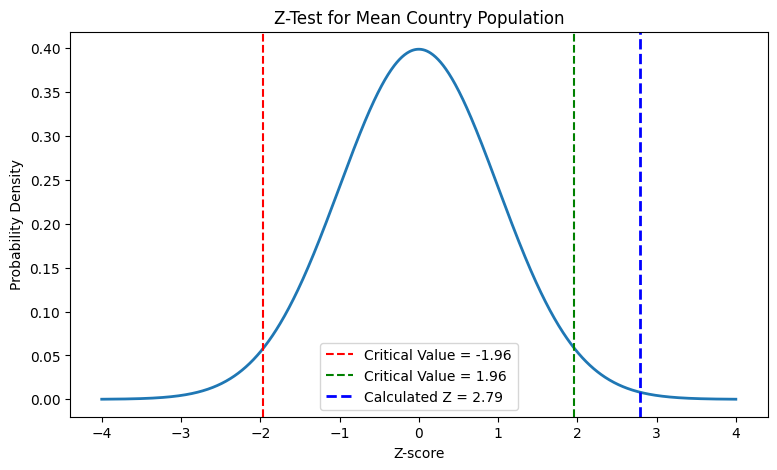

In [91]:
# Graph for Z-test

x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

plt.figure(figsize=(9, 5))
plt.plot(x, y, linewidth=2)

# Critical values for alpha = 0.05
z_critical = 1.96

plt.axvline(
    -z_critical,
    color="red",
    linestyle="--",
    label="Critical Value = -1.96"
)

plt.axvline(
    z_critical,
    color="green",
    linestyle="--",
    label="Critical Value = 1.96"
)

plt.axvline(
    z_score,
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"Calculated Z = {z_score:.2f}"
)

plt.xlabel("Z-score")
plt.ylabel("Probability Density")
plt.title("Z-Test for Mean Country Population")
plt.legend()
plt.show()

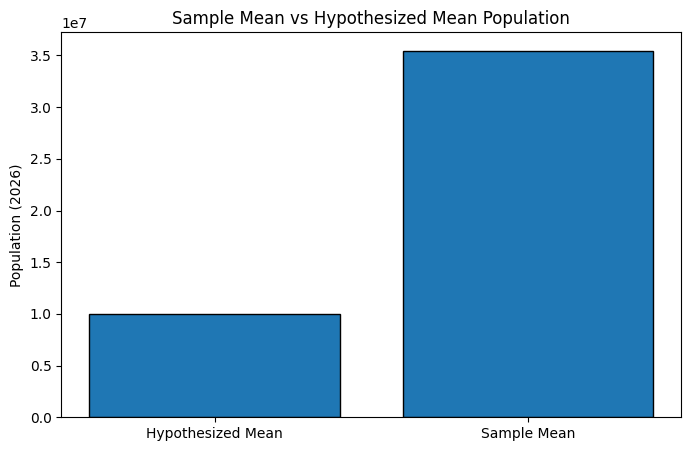

In [92]:
# Mean VS Hypothesized Mean

plt.figure(figsize=(8, 5))

values = [mu, sample_mean]
labels = ["Hypothesized Mean", "Sample Mean"]

plt.bar(labels, values, edgecolor="black")

plt.title("Sample Mean vs Hypothesized Mean Population")
plt.ylabel("Population (2026)")

plt.show()
plt.show()

In [93]:
# Two Sample t - Test

In [94]:
# Select the two most common population groups

population_groups = pd.cut(
    clean_df["Population 2026"],
    bins=[0, 1_000_000, 10_000_000, 100_000_000, float("inf")],
    labels=["Under 1M", "1M–10M", "10M–100M", "Over 100M"]
)

groups = population_groups.value_counts().head(2).index

# Get population values for both groups

group1 = clean_df.loc[
    population_groups == groups[0],
    "Population 2026"
].dropna()

group2 = clean_df.loc[
    population_groups == groups[1],
    "Population 2026"
].dropna()

print("Group 1:", groups[0], "| Countries:", len(group1))
print("Group 2:", groups[1], "| Countries:", len(group2))

Group 1: 10M–100M | Countries: 78
Group 2: Under 1M | Countries: 74


In [96]:
# Calculate statistics for both population groups

print("Population Group 1:", groups[0])
print("Sample Size 1:", len(group1))
print("Mean Population 1:", np.mean(group1))
print("Standard Deviation 1:", np.std(group1, ddof=1))

print("\nPopulation Group 2:", groups[1])
print("Sample Size 2:", len(group2))
print("Mean Population 2:", np.mean(group2))
print("Standard Deviation 2:", np.std(group2, ddof=1))

Population Group 1: 10M–100M
Sample Size 1: 78
Mean Population 1: 32674340.17948718
Standard Deviation 1: 20421773.52099678

Population Group 2: Under 1M
Sample Size 2: 74
Mean Population 2: 236772.22972972973
Standard Deviation 2: 271918.94171259407


In [97]:
# Perform two-sample t-test

t_statistic, p_value = stats.ttest_ind(
    group1, group2, equal_var=False
)

print("Two Sample T-Test")
print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 4))

Two Sample T-Test
T-statistic: 14.0269
P-value: 0.0


In [98]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("There is a significant difference in the mean populations between the two population groups.")

else:
    print("Fail to reject the null hypothesis")
    print("There is insufficient evidence of a significant difference in the mean populations between the two population groups.")

Reject the null hypothesis
There is a significant difference in the mean populations between the two population groups.


In [99]:
# Paired t Test

In [100]:
# Select population and land area for the same countries

paired_data = clean_df[
    ["Population 2026", "Land Area (KmÂ²)"]
].dropna()

population = paired_data["Population 2026"]
land_area = paired_data["Land Area (KmÂ²)"]

print("Mean Population:", population.mean())
print("Mean Land Area:", land_area.mean())

mean_difference = population.mean() - land_area.mean()

print("Mean Difference:", mean_difference)

Mean Population: 35465139.68376068
Mean Land Area: 555956.8076923077
Mean Difference: 34909182.876068376


In [101]:
# Perform paired t-test

t_statistic, p_value = stats.ttest_rel(population, land_area)

print("Paired T-Test")
print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 4))

Paired T-Test
T-statistic: 3.8494
P-value: 0.0002


In [102]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("There is a significant difference in the mean population and land area.")

else:
    print("Fail to reject the null hypothesis")
    print("There is insufficient evidence of a significant difference in the mean population and land area.")

Reject the null hypothesis
There is a significant difference in the mean population and land area.


In [103]:
# Chi Square Test

In [104]:
# Create a temporary dataframe using actual dataset columns

chi_df = clean_df[["Country (or dependency)", "Population 2026"]].dropna().copy()

# Group countries into population categories

chi_df["Population Group"] = pd.cut(
    chi_df["Population 2026"],
    bins=[0, 1_000_000, 10_000_000, 100_000_000, float("inf")],
    labels=["Under 1M", "1M–10M", "10M–100M", "Over 100M"]
)

chi_df = chi_df.dropna(subset=["Population Group"])

chi_df.head()

,Country (or dependency),Population 2026,Population Group
0,India,1476625576,Over 100M
1,China,1412914089,Over 100M
2,United States,349035494,Over 100M
3,Indonesia,287886782,Over 100M
4,Pakistan,259299791,Over 100M


In [105]:
# Create contingency table

contingency_table = pd.crosstab(
    chi_df["Population Group"],
    chi_df["Country (or dependency)"]
)

print("Contingency Table:")
print(contingency_table)

Contingency Table:
Country (or dependency)  Afghanistan  Albania  Algeria  American Samoa  \
Population Group                                                         
Under 1M                           0        0        0               1   
1M–10M                             0        1        0               0   
10M–100M                           1        0        1               0   
Over 100M                          0        0        0               0   

Country (or dependency)  Andorra  Angola  Anguilla  Antigua and Barbuda  \
Population Group                                                          
Under 1M                       1       0         1                    1   
1M–10M                         0       0         0                    0   
10M–100M                       0       1         0                    0   
Over 100M                      0       0         0                    0   

Country (or dependency)  Argentina  Armenia  ...  Uruguay  Uzbekistan  \
Population G

In [106]:
# Perform Chi-Square Test

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print("Chi-Square Test")
print("Chi-Square Statistic:", round(chi2, 4))
print("P-value:", round(p_value, 4))
print("Degrees of Freedom:", dof)

Chi-Square Test
Chi-Square Statistic: 702.0
P-value: 0.461
Degrees of Freedom: 699


In [107]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("There is a significant difference in the mean population and land area.")

else:
    print("Fail to reject the null hypothesis")
    print("There is insufficient evidence of a significant difference in the mean population and land area.")

Fail to reject the null hypothesis
There is insufficient evidence of a significant difference in the mean population and land area.


In [108]:
# Anova Test

In [109]:
# Select three common population groups

population_groups = pd.cut(
    clean_df["Population 2026"],
    bins=[0, 1_000_000, 10_000_000, 100_000_000, float("inf")],
    labels=["Under 1M", "1M–10M", "10M–100M", "Over 100M"]
)

groups = population_groups.value_counts().head(3).index

group1 = clean_df.loc[
    population_groups == groups[0],
    "Population 2026"
].dropna()

group2 = clean_df.loc[
    population_groups == groups[1],
    "Population 2026"
].dropna()

group3 = clean_df.loc[
    population_groups == groups[2],
    "Population 2026"
].dropna()

print("Selected Groups:", list(groups))
print("Group Sizes:", len(group1), len(group2), len(group3))

Selected Groups: ['10M–100M', 'Under 1M', '1M–10M']
Group Sizes: 78 74 66


In [110]:
# Display group information

print("Mean Population of", groups[0], ":", group1.mean())
print("Mean Population of", groups[1], ":", group2.mean())
print("Mean Population of", groups[2], ":", group3.mean())

Mean Population of 10M–100M : 32674340.17948718
Mean Population of Under 1M : 236772.22972972973
Mean Population of 1M–10M : 4832900.939393939


In [111]:
# Perform One-Way ANOVA

f_statistic, p_value = stats.f_oneway(
    group1, group2, group3
)

print("One-Way ANOVA Results")
print("F-statistic:", round(f_statistic, 4))
print("P-value:", round(p_value, 4))

One-Way ANOVA Results
F-statistic: 154.0281
P-value: 0.0


In [113]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("There is a significant difference in the mean population and land area.")

else:
    print("Fail to reject the null hypothesis")
    print("There is insufficient evidence of a significant difference in the mean population and land area.")

Reject the null hypothesis
There is a significant difference in the mean population and land area.


In [114]:
# Relationship Analysis - Covariance and Correlation
# Pearson and Spearman Correlation


 Population 2026 vs Land Area (KmÂ²)

Covariance: 105557042760972.69

Pearson Correlation: 0.4476
Pearson p-value: 6.311251057271694e-13

Pearson Decision: Reject the Null Hypothesis
There is a significant linear relationship.

Spearman Correlation: 0.8576
Spearman p-value: 6.261242131835863e-69

Spearman Decision: Reject the Null Hypothesis
There is a significant monotonic relationship.


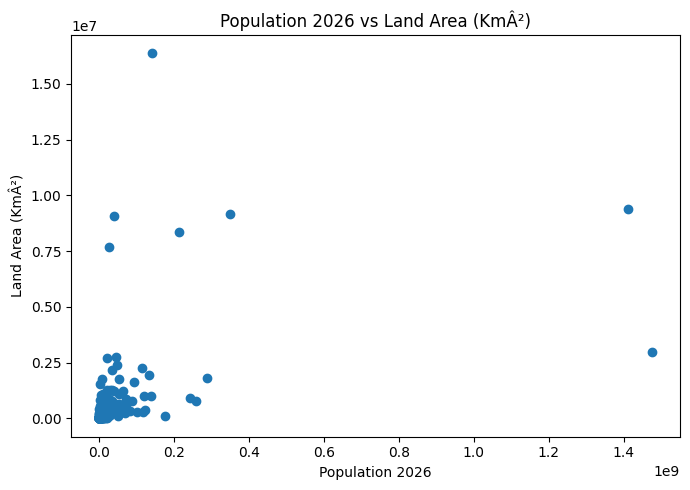


 Population 2026 vs Density (P/KmÂ²)

Covariance: -8542803779.0059

Pearson Correlation: -0.0255
Pearson p-value: 0.6980958159401489

Pearson Decision: Fail to Reject the Null Hypothesis
There is not a significant linear relationship.

Spearman Correlation: -0.1023
Spearman p-value: 0.11848756089515879

Spearman Decision: Fail to Reject the Null Hypothesis
There is not a significant monotonic relationship.


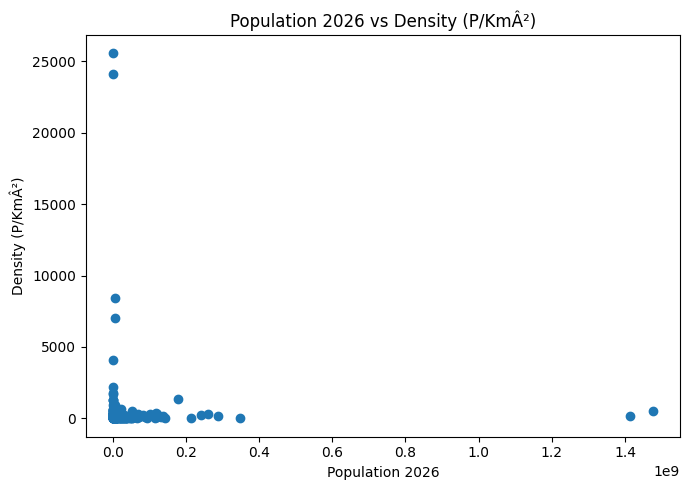


 Population 2026 vs Median Age

Covariance: -21203297.8246

Pearson Correlation: -0.0153
Pearson p-value: 0.8153847003387692

Pearson Decision: Fail to Reject the Null Hypothesis
There is not a significant linear relationship.

Spearman Correlation: -0.2729
Spearman p-value: 2.3015940904339602e-05

Spearman Decision: Reject the Null Hypothesis
There is a significant monotonic relationship.


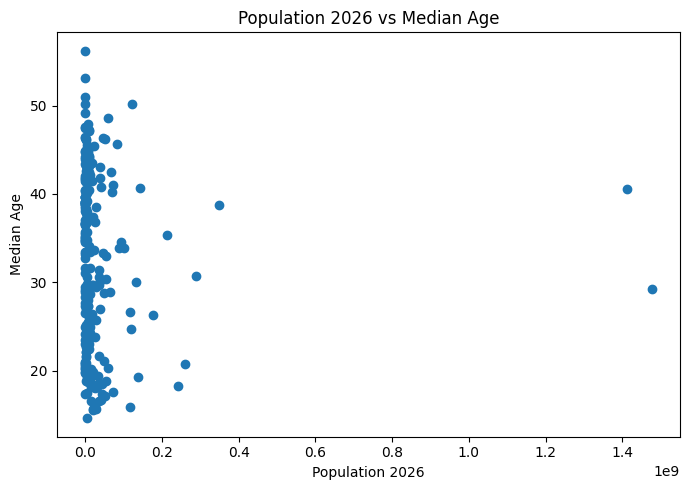


 Population 2026 vs Fert. Rate

Covariance: -4622545.4875

Pearson Correlation: -0.03
Pearson p-value: 0.6476491729824982

Pearson Decision: Fail to Reject the Null Hypothesis
There is not a significant linear relationship.

Spearman Correlation: 0.1958
Spearman p-value: 0.0026259405998393624

Spearman Decision: Reject the Null Hypothesis
There is a significant monotonic relationship.


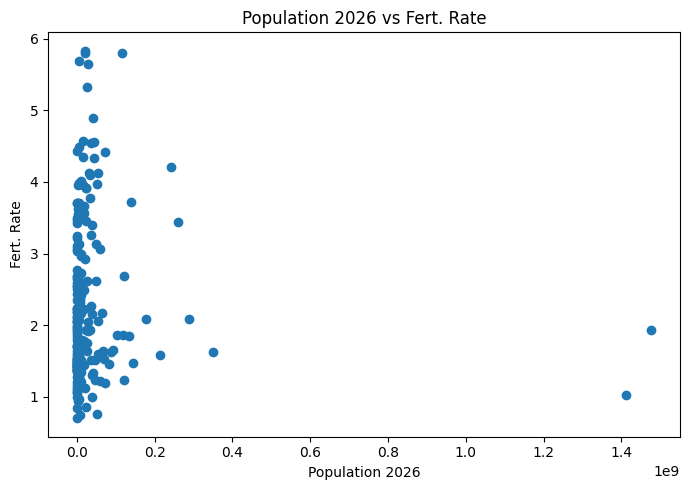

In [115]:
# Define pairs of features

pairs = [
    ("Population 2026", "Land Area (KmÂ²)"),
    ("Population 2026", "Density (P/KmÂ²)"),
    ("Population 2026", "Median Age"),
    ("Population 2026", "Fert. Rate")
]

# Correlation analysis

for x, y in pairs:

    data = clean_df[[x, y]].dropna()

    print("\n", x, "vs", y)

    # Covariance
    covariance = data[x].cov(data[y])
    print("\nCovariance:", round(covariance, 4))

    # Pearson correlation
    pearson_corr, pearson_p = stats.pearsonr(data[x], data[y])

    print("\nPearson Correlation:", round(pearson_corr, 4))
    print("Pearson p-value:", pearson_p)

    if pearson_p < alpha:
        print("\nPearson Decision: Reject the Null Hypothesis")
        print("There is a significant linear relationship.")
    else:
        print("\nPearson Decision: Fail to Reject the Null Hypothesis")
        print("There is not a significant linear relationship.")

    # Spearman correlation
    spearman_corr, spearman_p = stats.spearmanr(data[x], data[y])

    print("\nSpearman Correlation:", round(spearman_corr, 4))
    print("Spearman p-value:", spearman_p)

    if spearman_p < alpha:
        print("\nSpearman Decision: Reject the Null Hypothesis")
        print("There is a significant monotonic relationship.")
    else:
        print("\nSpearman Decision: Fail to Reject the Null Hypothesis")
        print("There is not a significant monotonic relationship.")

    # Scatter plot
    plt.figure(figsize=(7, 5))
    plt.scatter(data[x], data[y])
    plt.title(x + " vs " + y)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.tight_layout()
    plt.show()


 Population 2026
Minimum: 506
Maximum: 1476625576
Median: 5776466.5
Skewness: 9.07


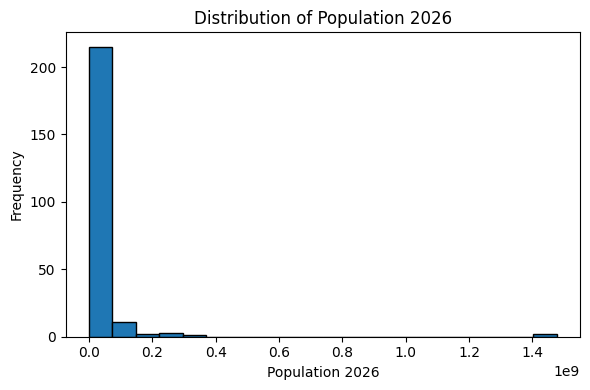


 Land Area (KmÂ²)
Minimum: 0
Maximum: 16376870
Median: 79720.0
Skewness: 6.07


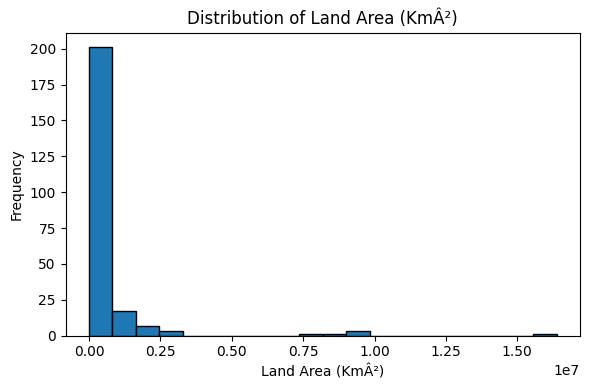


 Median Age
Minimum: 14.6
Maximum: 56.2
Median: 33.349999999999994
Skewness: -0.01


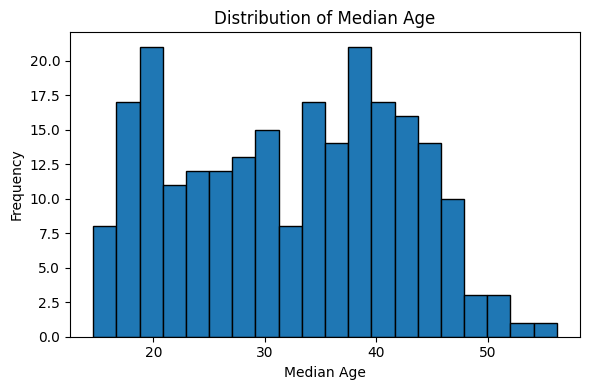

In [116]:
# Choosing target variables

targets = [
    "Population 2026",
    "Land Area (KmÂ²)",
    "Median Age"
]

for column in targets:
    data = clean_df[column].dropna()

    print("\n", column)
    print("Minimum:", data.min())
    print("Maximum:", data.max())
    print("Median:", data.median())
    print("Skewness:", round(data.skew(), 2))

    plt.figure(figsize=(6, 4))
    plt.hist(data, bins=20, edgecolor="black")
    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [117]:
# Since Population 2026 is our dependent variable,
# we choose it as the target variable for analysis.

In [118]:
# Multiple Linear Regression alongwith Lasso and RIdge Regression

In [119]:
from sklearn.model_selection import train_test_split

# Independent variables
features = [
    "Land Area (KmÂ²)",
    "Density (P/KmÂ²)",
    "Median Age",
    "Fert. Rate"
]

# Dependent variable
target = "Population 2026"

# Keep rows where population was originally recorded
valid_rows = df[target].notna()

X = clean_df.loc[valid_rows, features].copy()
y = clean_df.loc[valid_rows, target].copy()

# Remove rows with missing values in the selected features
valid_data = pd.concat([X, y], axis=1).dropna()
X = valid_data[features]
y = valid_data[target]

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Total usable rows:", len(X))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Independent variables:", features)
print("Dependent variable:", target)

Total usable rows: 234
Training rows: 187
Testing rows: 47
Independent variables: ['Land Area (KmÂ²)', 'Density (P/KmÂ²)', 'Median Age', 'Fert. Rate']
Dependent variable: Population 2026


In [120]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create the Multiple Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Predict population for the test data
linear_pred = linear_model.predict(X_test)

print("Multiple Linear Regression Results")
print("-" * 50)
print("Intercept:", round(linear_model.intercept_, 2))
print("Coefficients:", linear_model.coef_)

# Evaluate the model
print("Mean Absolute Error:", mean_absolute_error(y_test, linear_pred))
print("Mean Squared Error:", mean_squared_error(y_test, linear_pred))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, linear_pred)))
print("R² Score:", r2_score(y_test, linear_pred))

Multiple Linear Regression Results
--------------------------------------------------
Intercept: 150962087.39
Coefficients: [ 3.65671513e+01  5.70167015e+02 -2.60096997e+06 -2.27713899e+07]
Mean Absolute Error: 22117896.52517284
Mean Squared Error: 813281718257949.6
Root Mean Squared Error: 28518094.57621511
R² Score: 0.3634343389058975


In [121]:
# Scaling is useful for Lasso and Ridge

In [122]:
from sklearn.preprocessing import StandardScaler

# Standardize the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [123]:
from sklearn.linear_model import Ridge

# Create the Ridge Regression model
ridge_model = Ridge(alpha=1.0)

# Train the model using scaled data
ridge_model.fit(X_train_scaled, y_train)

# Predict country population
ridge_pred = ridge_model.predict(X_test_scaled)

print("Ridge Regression")
print("-" * 50)

print("Alpha:", ridge_model.alpha)
print("Intercept:", round(ridge_model.intercept_, 2))
print("Coefficients:", ridge_model.coef_)

Ridge Regression
--------------------------------------------------
Alpha: 1.0
Intercept: 38946363.68
Coefficients: [ 67927731.0606222    1425563.80032721 -24730818.09171389
 -25137536.88323963]


In [124]:
from sklearn.linear_model import Lasso

# Create the Lasso Regression model
lasso_model = Lasso(alpha=0.1)

# Train the model using scaled data
lasso_model.fit(X_train_scaled, y_train)

# Predict country population
lasso_pred = lasso_model.predict(X_test_scaled)

print("Lasso Regression")
print("-" * 50)

print("Alpha:", lasso_model.alpha)
print("Intercept:", round(lasso_model.intercept_, 2))
print("Coefficients:", lasso_model.coef_)

Lasso Regression
--------------------------------------------------
Alpha: 0.1
Intercept: 38946363.68
Coefficients: [ 68302878.19066235   1524853.78555993 -25672409.12509247
 -26043793.60893131]


In [125]:
# Decision Tree Regression

from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

# Train the model
tree_model.fit(X_train, y_train)

# Predict country population
tree_pred = tree_model.predict(X_test)

print("Decision Tree Regression")
print("-" * 50)

print("Maximum Depth:", tree_model.max_depth)

Decision Tree Regression
--------------------------------------------------
Maximum Depth: 3


In [126]:
# Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100, max_depth=3, random_state=42
)

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)

print("Random Forest Regression")
print("-" * 50)

print("Number of Trees:", forest_model.n_estimators)
print("Maximum Depth:", forest_model.max_depth)

Random Forest Regression
--------------------------------------------------
Number of Trees: 100
Maximum Depth: 3


In [127]:
prediction = {
    'Multiple Linear Regression': linear_pred,
    'Ridge Regression': ridge_pred,
    'Lasso Regression': lasso_pred,
    'Decision Tree Regression': tree_pred,
    'Random Forest Regression': forest_pred
}

In [128]:
results = []

for model_name, prediction in prediction.items():

    mae = mean_absolute_error(y_test, prediction)

    mse = mean_squared_error(y_test, prediction)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, prediction)

    results.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,MSE,RMSE,R2
0,Multiple Linear Regression,2.211790e+07,8.132817e+14,2.851809e+07,0.363434
1,Ridge Regression,2.193956e+07,8.048491e+14,2.836986e+07,0.370035
2,Lasso Regression,2.211790e+07,8.132817e+14,2.851809e+07,0.363434
3,Decision Tree Regression,2.120207e+07,1.391983e+15,3.730929e+07,-0.089522
4,Random Forest Regression,1.376503e+07,5.184410e+14,2.276930e+07,0.594210


In [129]:
models = {
    'Multiple Linear Regression': linear_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model,
    'Decision Tree Regression': tree_model,
    'Random Forest Regression': forest_model
}

In [130]:
best_model_name = results_df.loc[
    results_df['R2'].idxmax(), 'Model'
]

best_model1 = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest Regression


In [131]:
best_model1

RandomForestRegressor(max_depth=3, random_state=42)

In [132]:
import joblib

joblib.dump(best_model1, 'best_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

joblib.dump(best_model_name, 'best_model_name.pkl')

['best_model_name.pkl']

In [133]:
model = joblib.load('best_model.pkl')

scaler = joblib.load('scaler.pkl')

best_model_name = joblib.load('best_model_name.pkl')

In [135]:
import gradio as gr
import pandas as pd

def predict_population(land_area, density, median_age, fert_rate):
    try:
        # Prepare input using the same feature names and order as training
        input_data = pd.DataFrame({
            "Land Area (KmÂ²)": [land_area],
            "Density (P/KmÂ²)": [density],
            "Median Age": [median_age],
            "Fert. Rate": [fert_rate]
        })

        # Scale inputs only for Ridge and Lasso models
        if best_model_name in ["Ridge Regression", "Lasso Regression"]:
            input_data = scaler.transform(input_data)

        prediction = model.predict(input_data)[0]
        prediction = max(0, prediction)

        return (
            f"🌍 Predicted Population (2026): {prediction:,.0f}\n\n"
            f"🤖 Model Used: {best_model_name}"
        )

    except Exception as e:
        return f"Error: {str(e)}"


with gr.Blocks(theme=gr.themes.Soft(), title="World Population Predictor") as app:

    gr.Markdown("""
    # 🌍 World Population Prediction System
    ### Predict a country's population using geographical and demographic features.
    Enter the country's details below to generate a prediction.
    """)

    with gr.Row():
        with gr.Column():
            land_area = gr.Number(
                label="Land Area (Km²)",
                value=100000
            )
            density = gr.Number(
                label="Population Density (people/Km²)",
                value=100
            )

        with gr.Column():
            median_age = gr.Number(
                label="Median Age",
                value=30
            )
            fert_rate = gr.Number(
                label="Fertility Rate",
                value=2.0
            )

    predict_btn = gr.Button("🔮 Predict Population", variant="primary")

    output = gr.Textbox(
        label="Prediction Result",
        lines=4
    )

    predict_btn.click(
        fn=predict_population,
        inputs=[land_area, density, median_age, fert_rate],
        outputs=output
    )

    gr.Markdown(f"**Selected Model:** {best_model_name}")

app.launch()

/tmp/ipykernel_1978/2984129995.py:30: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="World Population Predictor") as app:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/29 13:32:55 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused


<IPython.core.display.Javascript object>